# Lab 3. Burrows' Delta

Nine public-domain books, 5,000-word passages, distances on the most frequent words.

In [1]:
import json, sys, statistics
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../analysis")
from features import *

DATA = Path("../web/public/data")
essays = json.loads((DATA / "essays.json").read_text())["essays"]
wordlist = set(json.loads((DATA / "wordlist.json").read_text()))
markers = json.loads((DATA / "markers.json").read_text())
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, OCHRE, INK = "#008f86", "#b07d12", "#1c2b3a"


In [2]:
lit = json.loads((DATA / "literary.json").read_text())
chunks, vocab = lit["chunks"], lit["vocab"]
print(len(chunks), "passages;", Counter(c["author"] for c in chunks))

def nn_accuracy(n_mfw):
    D = burrows_delta(chunks, vocab, n_mfw)
    ok = 0
    for i, c in enumerate(chunks):
        j = min((k for k in range(len(chunks)) if k != i), key=lambda k: D[i][k])
        ok += chunks[j]["author"] == c["author"]
    return ok

pd.Series({n: nn_accuracy(n) for n in [10, 20, 50, 100, 200, 300]}, name="correct of 69")

69 passages; Counter({'Austen': 24, 'Chesterton': 24, 'Melville': 8, 'Edgeworth': 8, 'Carroll': 5})


10     55
20     61
50     67
100    69
200    69
300    69
Name: correct of 69, dtype: int64

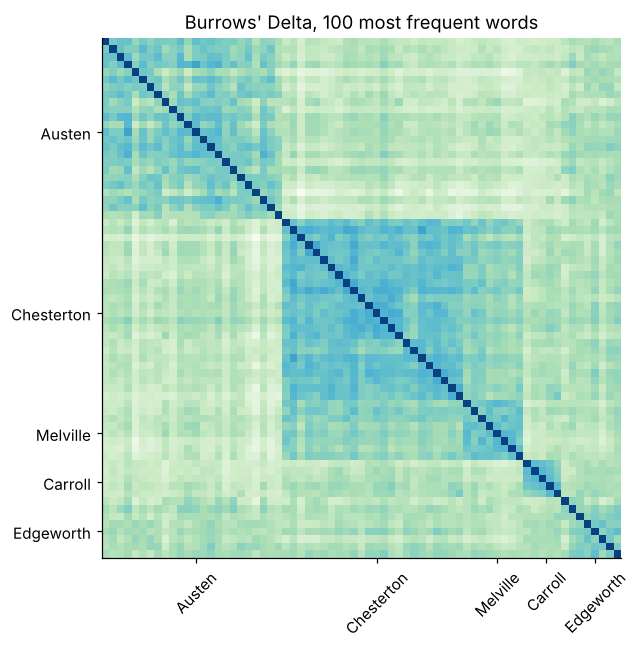

In [3]:
D = burrows_delta(chunks, vocab, 100)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(D, cmap="GnBu_r")
authors = [c["author"] for c in chunks]
ticks = [authors.index(a) + authors.count(a) / 2 for a in dict.fromkeys(authors)]
ax.set_xticks(ticks, list(dict.fromkeys(authors)), rotation=45); ax.set_yticks(ticks, list(dict.fromkeys(authors)))
ax.set_title("Burrows' Delta, 100 most frequent words"); plt.tight_layout()